# Processamento de Linguagem Natural (PLN): Processamento de Texto e Análise de Sentimentos com Deep Learning

Neste trabalho, realizaremos o processamento de texto (Parte 1) utilizando as bibliotecas SpaCy e NLTK. Em seguida, na Parte 2, realizaremos uma análise de sentimentos utilizando uma Rede Neural Recorrente LSTM, com o objetivo de avaliar como os viajantes expressaram seus sentimentos em mensagens no Twitter sobre as companhias aéreas (US Airline Sentiment).

Dataset adaptado de: https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment.

# **ATIVIDADE:**

**Descrição:**

Nesta atividade, você receberá um código dividido em duas partes para explorar técnicas de Processamento de Linguagem Natural (PLN). A Parte 1 envolve o processamento de texto, enquanto a Parte 2 foca na análise de sentimentos por meio de uma Rede Neural Recorrente LSTM implementada. Sua tarefa será analisar o código em detalhes, compreender os conceitos aplicados e documentar as principais etapas e configurações do modelo.



**Instruções:**

1. Preencha o código com comentários em cada linha, explicando sua função e propósito.
2. Descreva como o processamento dos dados de texto é realizado. Identifique e comente as etapas, explicando como o texto é transformado em dados adequados para o modelo.
3. Identifique e explique sobre cada camada do modelo (Embedding, LSTM, etc.).
Identifique como o modelo trata os dados de entrada, incluindo o uso de Tokenizer e pad_sequences.
4. Identifique quais técnicas de regularização ou otimização formam utilizadas no código e explique como elas contribuem para o desempenho e a generalização do modelo.
5. Comente sobre as funções de ativação utilizadas nas camadas intermediárias e na camada de saída.
6. Descreva os hiperparâmetros e ajustes do modelo, como a taxa de aprendizado, número de épocas de treinamento e o tratamento dos conjuntos de dados de treinamento e teste.
7. Faça uma avaliação descritiva dos resultados.
8. No modelo de LSTM, faça uma avaliação descritiva da qualidade do modelo treinado e sugira possíveis melhorias no modelo ou no processo de treinamento, justificando suas sugestões.


**Entregável:**

Prepare uma análise detalhada do código fornecido, explicando cada etapa.
Faça um resumo da arquitetura do modelo, destacando suas características principais. Faça observações sobre os resultados obtidos e descreva propostas de melhorias.

Esta atividade tem como objetivo consolidar o conhecimento sobre Redes Neurais Artificiais aplicadas ao Processamento de Linguagem Natural (PLN).

## PARTE 01: PROCESSAMENTO DE TEXTO

## Importação das bibliotecas

In [1]:
!pip install -q spacy

In [2]:
import bs4 as bs
import urllib.request
import nltk
import spacy

In [3]:
!python3 -m spacy download pt_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 63.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Marcação POS

- POS (part-of-speech) atribui para as palavras partes da fala, como substantivos, adjetivos, verbos
- Importante para a detecção de entidades no texto, pois primeiro é necessário saber o que o texto contém
- Lista de tokens: https://spacy.io/api/annotation#pos-tagging
- Português: https://www.sketchengine.eu/portuguese-freeling-part-of-speech-tagset/

In [4]:
pln = spacy.load('pt_core_news_sm')
pln

In [79]:
documento = pln('Estou aprendendo processamento de linguagem natural. Eu estou cursando Sistemas de Informação, na FURB em Blumenau')

###Tokenização

Explique como funciona a tokenização. Em seguida, analise os resultados gerados pelo código apresentado, interpretando o que significa.

In [80]:
type(documento)

spacy.tokens.doc.Doc

In [81]:
for token in documento:
  print(token.text, token.pos_)

Estou AUX
aprendendo VERB
processamento NOUN
de ADP
linguagem NOUN
natural ADJ
. PUNCT
Eu PRON
estou AUX
cursando VERB
Sistemas PROPN
de ADP
Informação PROPN
, PUNCT
na ADP
FURB PROPN
em ADP
Blumenau PROPN


### Lematização e Stemização

Explique as funções da lematização e da stemização, detalhando seus objetivos e diferenças. Em seguida, analise os resultados gerados pelos códigos apresentados, interpretando o que eles significam.

In [82]:
for token in documento:
  print(token.text, token.lemma_)

Estou estar
aprendendo aprender
processamento processamento
de de
linguagem linguagem
natural natural
. .
Eu eu
estou estar
cursando cursar
Sistemas Sistemas
de de
Informação Informação
, ,
na em o
FURB FURB
em em
Blumenau Blumenau


In [78]:
doc = pln('encontrei encontraram encontrarão encontrariam cursando curso cursei')
[token.lemma_ for token in doc]

['encontrar',
 'encontrar',
 'encontrar',
 'encontrar',
 'cursar',
 'curso',
 'cursar']

In [12]:
import nltk
nltk.download('rslp')

[nltk_data] Downloading package rslp to /root/nltk_data...
[nltk_data]   Package rslp is already up-to-date!


True

In [13]:
stemmer = nltk.stem.RSLPStemmer()
stemmer.stem('aprender')

'aprend'

In [14]:
for token in documento:
  print(token.text, token.lemma_, stemmer.stem(token.text))

Estou estar est
aprendendo aprender aprend
processamento processamento process
de de de
linguagem linguagem lingu
natural natural natur
, , ,
curso curso curs
de de de
Sistemas Sistemas sistem
de de de
Informação Informação inform
, , ,
na em o na
FURB FURB furb
em em em
Blumenau Blumenau blumenau


## Buscas em textos com spaCy
### Carregar texto da Web


In [15]:
dados = urllib.request.urlopen('https://pt.wikipedia.org/wiki/Intelig%C3%AAncia_artificial')

In [16]:
dados = dados.read()
dados

b'<!DOCTYPE html>\n<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-sticky-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 vector-feature-night-mode-enabled skin-theme-clientpref-day vector-toc-available" lang="pt" dir="ltr">\n<head>\n<meta charset="UTF-8">\n<title>Intelig\xc3\xaancia artificial \xe2\x80\x93 Wikip\xc3\xa9dia, a enciclop\xc3\xa9dia livre</title>\n<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-sticky-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-me

In [17]:
dados_html = bs.BeautifulSoup(dados, 'lxml')
dados_html

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-sticky-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 vector-feature-night-mode-enabled skin-theme-clientpref-day vector-toc-available" dir="ltr" lang="pt">
<head>
<meta charset="utf-8"/>
<title>Inteligência artificial – Wikipédia, a enciclopédia livre</title>
<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-sticky-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limi

In [18]:
paragrafos = dados_html.find_all('p')

In [19]:
len(paragrafos)

64

In [20]:
paragrafos[1]

<p>Algumas das principais áreas relacionadas à IA incluem:
</p>

In [21]:
paragrafos[1].text

'Algumas das principais áreas relacionadas à IA incluem:\n'

In [22]:
conteudo = ''
for p in paragrafos:
  conteudo += p.text

In [23]:
conteudo

'A inteligência artificial (de sigla: IA; do inglês: artificial intelligence, de sigla: AI) é um campo de estudo multidisciplinar que abrange varias áreas do conhecimento.[1][2] É também um conjunto de novas tecnologias que permitem aos aparelhos smart executarem várias funções avançadas de modo quase autônomo,[2][3] representando um marco histórico na computação moderna.[3] Embora seu desenvolvimento tenha avançado mais na ciência da computação, sua abordagem interdisciplinar envolve contribuições de diversas disciplina.\nAlgumas das principais áreas relacionadas à IA incluem:\nÉ difícil definir especificamente a Inteligência Artificial, mas ao longo do tempo seguiu essas quatro linhas de pensamento:[1]\nÉ um conceito amplo e que recebe tantas definições quanto significados diferentes à palavra inteligência.[4] É possível considerar algumas características básicas desses sistemas, como a capacidade de raciocínio (aplicar regras lógicas a um conjunto de dados disponíveis para chegar a 

In [24]:
conteudo = conteudo.lower()
conteudo

'a inteligência artificial (de sigla: ia; do inglês: artificial intelligence, de sigla: ai) é um campo de estudo multidisciplinar que abrange varias áreas do conhecimento.[1][2] é também um conjunto de novas tecnologias que permitem aos aparelhos smart executarem várias funções avançadas de modo quase autônomo,[2][3] representando um marco histórico na computação moderna.[3] embora seu desenvolvimento tenha avançado mais na ciência da computação, sua abordagem interdisciplinar envolve contribuições de diversas disciplina.\nalgumas das principais áreas relacionadas à ia incluem:\né difícil definir especificamente a inteligência artificial, mas ao longo do tempo seguiu essas quatro linhas de pensamento:[1]\né um conceito amplo e que recebe tantas definições quanto significados diferentes à palavra inteligência.[4] é possível considerar algumas características básicas desses sistemas, como a capacidade de raciocínio (aplicar regras lógicas a um conjunto de dados disponíveis para chegar a 

## Buscas em textos com spaCy

In [25]:
pln = spacy.load('pt_core_news_sm')
pln

In [26]:
string = 'turing'
token_pesquisa = pln(string)

In [27]:
pln.vocab

In [28]:
from spacy.matcher import PhraseMatcher
matcher = PhraseMatcher(pln.vocab)
matcher.add('SEARCH', None, token_pesquisa)

In [29]:
doc = pln(conteudo)
matches = matcher(doc)
matches

[(8661325627334373315, 3463, 3464),
 (8661325627334373315, 3473, 3474),
 (8661325627334373315, 3629, 3630),
 (8661325627334373315, 3634, 3635),
 (8661325627334373315, 3640, 3641),
 (8661325627334373315, 3703, 3704),
 (8661325627334373315, 4356, 4357),
 (8661325627334373315, 5573, 5574),
 (8661325627334373315, 5708, 5709),
 (8661325627334373315, 5803, 5804),
 (8661325627334373315, 5920, 5921)]

In [30]:
doc[3463:3464], doc[3463-5:3464+5]

(turing, uma contribuição prática de alan turing foi o que se chamou)

In [31]:
doc[3473:3474], doc[3473-5:3474+5]

(turing, chamou depois de teste de turing (tt),[34] de 1950)

In [32]:
matches[0], matches[0][1], matches[0][2]

((8661325627334373315, 3463, 3464), 3463, 3464)

In [33]:
from IPython.core.display import HTML
texto = ''
numero_palavras = 50
doc = pln(conteudo)
matches = matcher(doc)

display(HTML(f'<h1>{string.upper()}</h1>'))
display(HTML(f"""<p><strong>Resultados encontrados:</strong> {len(matches)}</p>"""))
for i in matches:
  inicio = i[1] - numero_palavras
  if inicio < 0:
    inicio = 0
  texto += str(doc[inicio:i[2] + numero_palavras]).replace(string, f"<mark>{string}</mark>")
  texto += "<br /><br />"
display(HTML(f"""... {texto} ... """))

## Extração de entidades nomeadas

- NER (Named-Entity Recognition)
- Encontrar e classificar entidades no texto, dependendo da base de dados que foi utilizada para o treinamento (pessoa, localização, empresa, numéricos)
- Usado em chatbots para saber o assunto falado
- Siglas: https://spacy.io/api/annotation#named-entities

In [34]:
for entidade in doc.ents:
  print(entidade.text, entidade.label_)

pensamento:[1 MISC
segunda guerra mundial MISC
computing machinery and intelligence MISC
alan PER
herbert simon PER
allen newell PER
john mccarthy PER
warren mcculloch PER
walter pitts PER
marvin minsky PER
frankenstein MISC
aristóteles PER
alexandre PER
herbert simon PER
john mccarthy PER
brasil LOC
allen newell PER
herbert simon PER
mccarty PER
marvin minsky PER
mit ORG
darthmouth LOC
estados unidos LOC
fifth generation MISC
japão LOC
prolog MISC
gpt-3[21 MISC
google ORG
wikipédia MISC
john mccarthy PER
andreas kaplan PER
michael haenlein definem PER
john mccarthy PER
john haugeland PER
good PER
w. grey walter PER
besta de johns hopkins ORG
universidade de princeton LOC
ratio club LOC
inglaterra LOC
david rumelhart PER
isaac asimov PER
steven spielberg PER
robótica.[8 ORG
stephen hawking PER
alan turing PER
turing PER
turing PER
turing PER
turing PER
turing PER
joseph weizenbaum PER
mit ORG
a.l.i.c.e MISC
java MISC
intelligence markup language PER
alicebots LOC
programáveis.[35][36 O

In [35]:
from spacy import displacy
displacy.render(doc, style = 'ent', jupyter = True)

## Nuvem de Palavras e Stop Words

In [36]:
from matplotlib.colors import ListedColormap
color_map = ListedColormap(['orange', 'green', 'red', 'magenta'])

In [37]:
from wordcloud import WordCloud
cloud = WordCloud(background_color = 'white', max_words = 100, colormap=color_map)

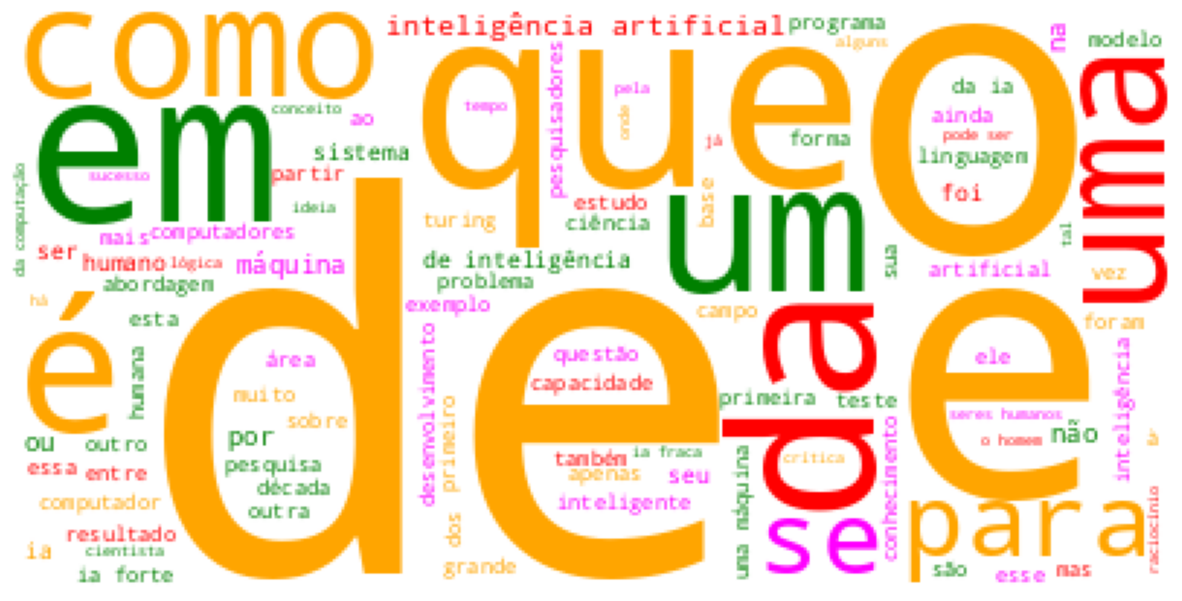

In [38]:
import matplotlib.pyplot as plt
cloud = cloud.generate(conteudo)
plt.figure(figsize=(15,15))
plt.imshow(cloud)
plt.axis('off')
plt.show()

Qual o problema do resultado apresentado na nuvem de palavras?

Explique para que são utilizadas as stop words em PLN.

In [39]:
from spacy.lang.pt.stop_words import STOP_WORDS
print(STOP_WORDS)

{'em', 'cinco', 'mal', 'sem', 'sois', 'estão', 'vinda', 'como', 'aí', 'obrigada', 'fostes', 'algumas', 'este', 'parece', 'nosso', 'tiveram', 'tente', 'menos', 'parte', 'esta', 'nível', 'menor', 'faz', 'nunca', 'sobre', 'forma', 'que', 'corrente', 'entre', 'quer', 'obrigado', 'cento', 'estes', 'toda', 'estás', 'minha', 'pela', 'desse', 'fomos', 'lugar', 'nove', 'custa', 'ver', 'vossa', 'dizem', 'fim', 'aquela', 'dá', 'direita', 'tua', 'cuja', 'nova', 'estivestes', 'tipo', 'nossas', 'és', 'os', 'é', 'à', 'somos', 'nuns', 'seus', 'contra', 'dos', 'agora', 'estado', 'primeira', 'meio', 'está', 'deste', 'vossos', 'fazem', 'vinte', 'até', 'sétima', 'enquanto', 'lado', 'minhas', 'tens', 'deverá', 'qual', 'oitava', 'possível', 'somente', 'grupo', 'maioria', 'desta', 'doze', 'grande', 'pois', 'num', 'três', 'nós', 'segunda', 'das', 'dois', 'fazes', 'de', 'vossas', 'vocês', 'quatro', 'seis', 'ontem', 'cujo', 'desde', 'bom', 'bem', 'você', 'muitos', 'com', 'elas', 'relação', 'fui', 'eventual', 'd

In [40]:
len(STOP_WORDS)

416

In [41]:
pln.vocab['caminhar'].is_stop

False

In [42]:
pln.vocab['usa'].is_stop

True

In [43]:
doc = pln(conteudo)
lista_token = []
for token in doc:
  lista_token.append(token.text)

In [44]:
print(lista_token)

['a', 'inteligência', 'artificial', '(', 'de', 'sigla', ':', 'ia', ';', 'do', 'inglês', ':', 'artificial', 'intelligence', ',', 'de', 'sigla', ':', 'ai', ')', 'é', 'um', 'campo', 'de', 'estudo', 'multidisciplinar', 'que', 'abrange', 'varias', 'áreas', 'do', 'conhecimento.[1][2', ']', 'é', 'também', 'um', 'conjunto', 'de', 'novas', 'tecnologias', 'que', 'permitem', 'aos', 'aparelhos', 'smart', 'executarem', 'várias', 'funções', 'avançadas', 'de', 'modo', 'quase', 'autônomo,[2][3', ']', 'representando', 'um', 'marco', 'histórico', 'na', 'computação', 'moderna.[3', ']', 'embora', 'seu', 'desenvolvimento', 'tenha', 'avançado', 'mais', 'na', 'ciência', 'da', 'computação', ',', 'sua', 'abordagem', 'interdisciplinar', 'envolve', 'contribuições', 'de', 'diversas', 'disciplina', '.', '\n', 'algumas', 'das', 'principais', 'áreas', 'relacionadas', 'à', 'ia', 'incluem', ':', '\n', 'é', 'difícil', 'definir', 'especificamente', 'a', 'inteligência', 'artificial', ',', 'mas', 'ao', 'longo', 'do', 'tem

In [45]:
len(lista_token)

6316

In [46]:
sem_stop = []
for palavra in lista_token:
  if pln.vocab[palavra].is_stop == False:
    sem_stop.append(palavra)

In [47]:
print(sem_stop)

['inteligência', 'artificial', '(', 'sigla', ':', 'ia', ';', 'inglês', ':', 'artificial', 'intelligence', ',', 'sigla', ':', 'ai', ')', 'campo', 'estudo', 'multidisciplinar', 'abrange', 'varias', 'áreas', 'conhecimento.[1][2', ']', 'conjunto', 'tecnologias', 'permitem', 'aparelhos', 'smart', 'executarem', 'várias', 'funções', 'avançadas', 'modo', 'quase', 'autônomo,[2][3', ']', 'representando', 'marco', 'histórico', 'computação', 'moderna.[3', ']', 'desenvolvimento', 'tenha', 'avançado', 'ciência', 'computação', ',', 'abordagem', 'interdisciplinar', 'envolve', 'contribuições', 'diversas', 'disciplina', '.', '\n', 'principais', 'áreas', 'relacionadas', 'ia', 'incluem', ':', '\n', 'difícil', 'definir', 'especificamente', 'inteligência', 'artificial', ',', 'longo', 'seguiu', 'linhas', 'pensamento:[1', ']', '\n', 'conceito', 'amplo', 'recebe', 'tantas', 'definições', 'significados', 'diferentes', 'palavra', 'inteligência.[4', ']', 'considerar', 'características', 'básicas', 'desses', 'sist

In [48]:
len(sem_stop)

3652

In [49]:
from matplotlib.colors import ListedColormap
color_map = ListedColormap(['orange', 'green', 'red', 'magenta'])

In [50]:
from wordcloud import WordCloud
cloud = WordCloud(background_color = 'white', max_words = 100, colormap=color_map)

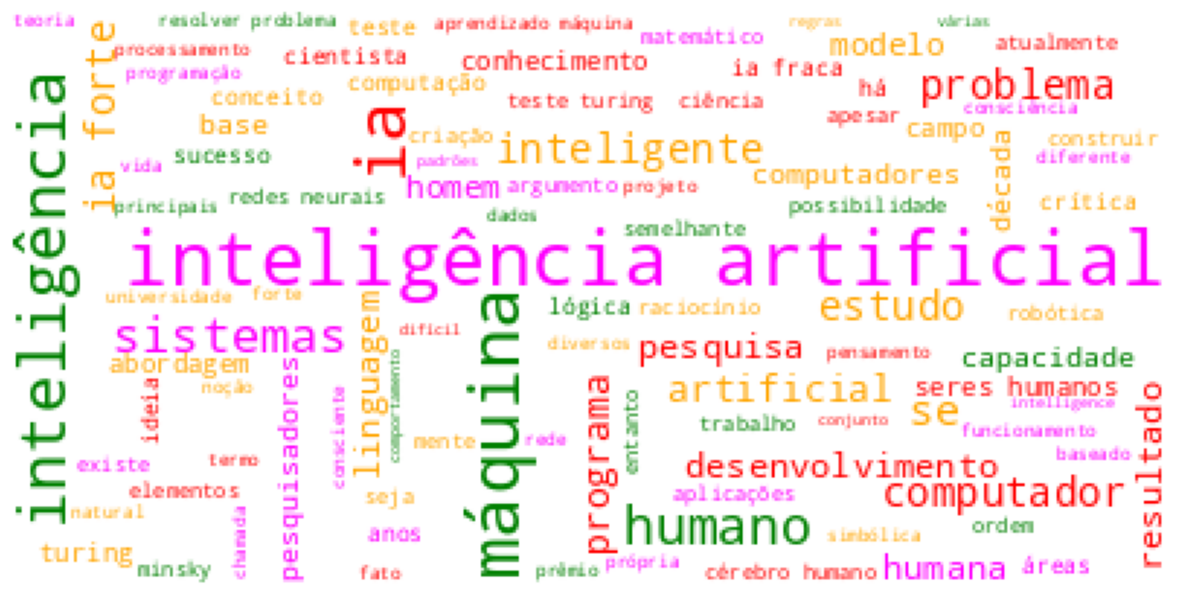

In [51]:
import matplotlib.pyplot as plt
cloud = cloud.generate(' '.join(sem_stop))
plt.figure(figsize=(15,15))
plt.imshow(cloud)
plt.axis('off')
plt.show()

# PARTE 2: ANÁLISE DE SENTIMENTOS UTILIZANDO REDE NEURAL RECORRENTE LSTM

## Importação das bibliotecas

In [52]:
pip install --upgrade tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.3/615.3 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 68.3 MB/s eta 0:00:00
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.17.1
    Uninstalling tensorboard-2.17.1:
      Successfully uninstalled tensorboard-2.17.1
  Attempting uninstall: tensorflow
    Found existing installation: tensorflow 2.17.1
    Uninstalling tensorflow-2.17.1:
      Successfully uninstalled tensorflow-2.17.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.17.0 requires tensorflow<2.18,>=2.17, but you have tensorflow 2.18.0 which is incompatible.


In [53]:
pip install keras

In [54]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Dense, Embedding, LSTM, SpatialDropout1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.utils import to_categorical
from google.colab import files
import numpy as np

In [55]:
files.upload()

Saving Tweets.csv to Tweets.csv


{'Tweets.csv': b'tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone\n570306133677760513,neutral,1.0,,,Virgin America,,cairdin,,0,@VirginAmerica What @dhepburn said.,,2015-02-24 11:35:52 -0800,,Eastern Time (US & Canada)\n570301130888122368,positive,0.3486,,0.0,Virgin America,,jnardino,,0,@VirginAmerica plus you\'ve added commercials to the experience... tacky.,,2015-02-24 11:15:59 -0800,,Pacific Time (US & Canada)\n570301083672813571,neutral,0.6837,,,Virgin America,,yvonnalynn,,0,@VirginAmerica I didn\'t today... Must mean I need to take another trip!,,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)\n570301031407624196,negative,1.0,Bad Flight,0.7033,Virgin America,,jnardino,,0,"@VirginAmerica it\'s really aggressive to blast obnoxious ""entertainment"" in your guests\' faces &amp; they have little 

In [56]:
Tweets = pd.read_csv("Tweets.csv")
Tweets.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [57]:
Tweets.groupby(['airline_sentiment']).size()

,0
airline_sentiment,
negative,9178
neutral,3099
positive,2363


In [58]:
Tweets = Tweets[Tweets['airline_sentiment_confidence'] > 0.8]

### Tokenização

In [59]:
token = Tokenizer(num_words=100)
token.fit_on_texts(Tweets['text'].values)

In [60]:
X = token.texts_to_sequences(Tweets['text'].values)
X = pad_sequences(X, padding="post", maxlen=100)

In [61]:
print(X)

[[97 62  0 ...  0  0  0]
 [97 99  1 ...  0  0  0]
 [97  9 99 ...  0  0  0]
 ...
 [13 98 93 ...  0  0  0]
 [13 89  1 ...  0  0  0]
 [13  6 23 ...  0  0  0]]


### One Hot Encoder

In [62]:
labelencoder = LabelEncoder()
y = labelencoder.fit_transform(Tweets['airline_sentiment'])
print(y)

[1 0 0 ... 0 1 0]


In [63]:
y = to_categorical(y)
print(y)

[[0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 ...
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [64]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3)
X_test

array([[13, 25,  4, ...,  0,  0,  0],
       [18, 63, 10, ...,  0,  0,  0],
       [13, 67, 43, ...,  0,  0,  0],
       ...,
       [ 8, 37, 11, ...,  0,  0,  0],
       [12,  3, 47, ...,  0,  0,  0],
       [18,  7,  1, ...,  0,  0,  0]], dtype=int32)

###Treinando a LSTM com Keras

In [65]:
modelo = Sequential()
modelo.add(Embedding(input_dim= len(token.word_index), output_dim=128))
modelo.add(SpatialDropout1D(0.2))
modelo.add(LSTM(units=196, dropout=0.2, recurrent_dropout=0, activation='tanh',
                recurrent_activation='sigmoid', unroll=False, use_bias=True))
modelo.add(Dense(units=3,activation="softmax"))

In [66]:
modelo.compile(loss='categorical_crossentropy', optimizer='adam', metrics = ['accuracy'])
print(modelo.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [67]:
modelo.fit(X_train, y_train, epochs=10, batch_size=30,verbose=True,validation_data=(X_test, y_test))

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 69s 271ms/step - accuracy: 0.6959 - loss: 0.8520 - val_accuracy: 0.6998 - val_loss: 0.8213
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 64s 262ms/step - accuracy: 0.7114 - loss: 0.8059 - val_accuracy: 0.6998 - val_loss: 0.8235
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 65s 264ms/step - accuracy: 0.7123 - loss: 0.8027 - val_accuracy: 0.6998 - val_loss: 0.8218
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 78s 249ms/step - accuracy: 0.7130 - loss: 0.8043 - val_accuracy: 0.6998 - val_loss: 0.8248
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 82s 251ms/step - accuracy: 0.7029 - loss: 0.8195 - val_accuracy: 0.6998 - val_loss: 0.8300
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 84s 259ms/step - accuracy: 0.7208 - loss: 0.7864 - val_accuracy: 0.6998 - val_loss: 0.8260
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 80s 249ms/step - accuracy: 0.7105 - loss: 0.8046 - val_accuracy: 0.6998 - val_loss: 0.8196
Epoch 8/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 82s 251ms/step - accuracy: 0.7118 - loss: 0

In [68]:
loss, accuracy = modelo.evaluate(X_test,y_test)
print("Loss: ", loss)
print("Accuracy: ", accuracy)

99/99 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.7016 - loss: 0.8178
Loss:  0.8199223279953003
Accuracy:  0.6998087763786316


In [69]:
prev = modelo.predict(X_test)
print(prev)

99/99 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step
[[0.67873216 0.16563171 0.15563604]
 [0.67873216 0.16563171 0.15563604]
 [0.67873216 0.16563171 0.15563604]
 ...
 [0.6787323  0.16563173 0.15563606]
 [0.6787323  0.16563171 0.15563606]
 [0.6787323  0.16563171 0.15563607]]
